In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect('../data/fraude.duckdb')

df = con.execute("SELECT * FROM gold_fraud").df()

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,es_fraude
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# Distribución de clases
print(df['es_fraude'].value_counts())
print(df['es_fraude'].value_counts(normalize=True) * 100)

es_fraude
0    284315
1       492
Name: count, dtype: int64
es_fraude
0    99.827251
1     0.172749
Name: proportion, dtype: float64


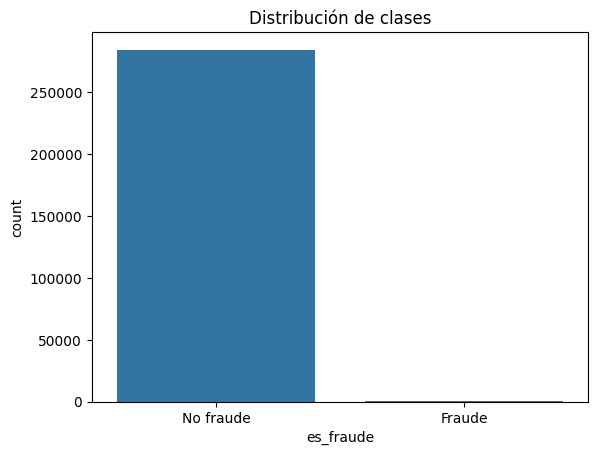

In [3]:
sns.countplot(x='es_fraude', data=df)
plt.title('Distribución de clases')
plt.xticks([0, 1], ['No fraude', 'Fraude'])
plt.show()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


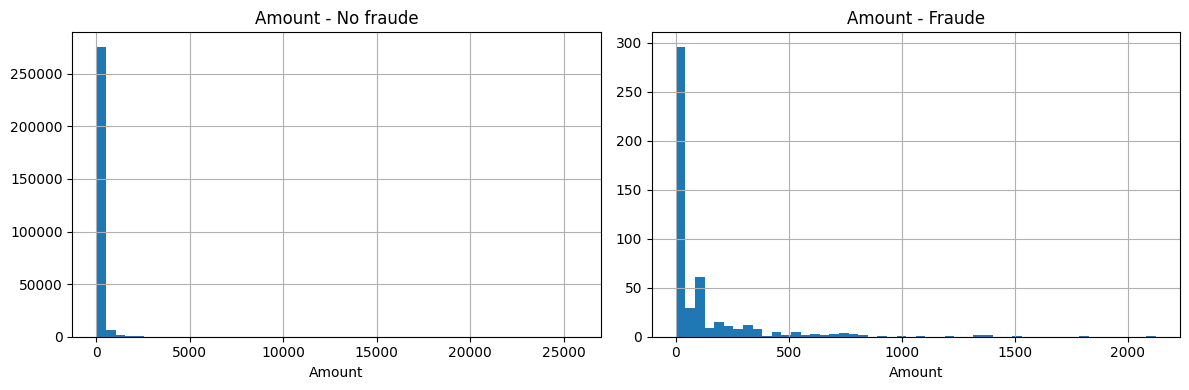

In [4]:
# Estadísticas descriptivas de Amount
print(df['Amount'].describe())

# Distribución de Amount por clase
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[df['es_fraude'] == 0]['Amount'].hist(bins=50, ax=axes[0])
axes[0].set_title('Amount - No fraude')
axes[0].set_xlabel('Amount')

df[df['es_fraude'] == 1]['Amount'].hist(bins=50, ax=axes[1])
axes[1].set_title('Amount - Fraude')
axes[1].set_xlabel('Amount')

plt.tight_layout()
plt.show()

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


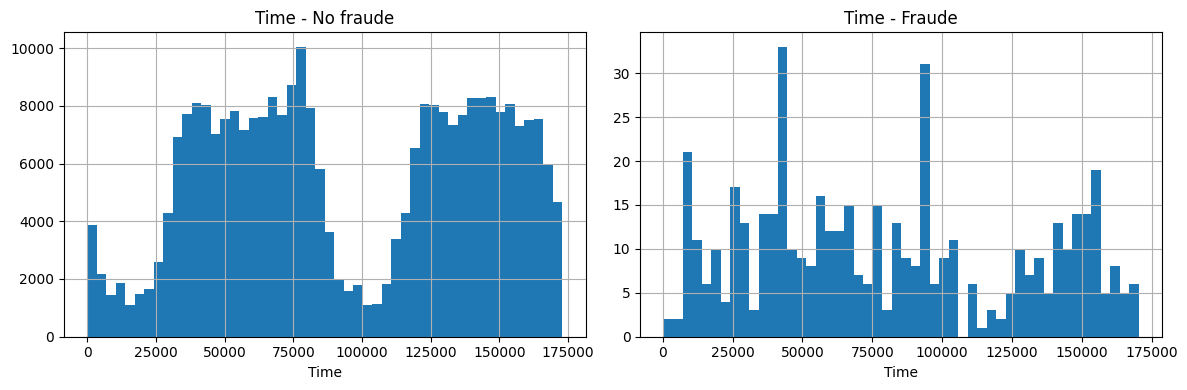

In [6]:
# # Estadísticas descriptivas de Amount
# print(df['Time'].describe())

# # Distribución de Time por clase
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# df[df['es_fraude'] == 0]['Time'].hist(bins=50, ax=axes[0])
# axes[0].set_title('Time - No fraude')
# axes[0].set_xlabel('Time')

# df[df['es_fraude'] == 1]['Time'].hist(bins=50, ax=axes[1])
# axes[1].set_title('Time - Fraude')
# axes[1].set_xlabel('Time')

# plt.tight_layout()
# plt.show()

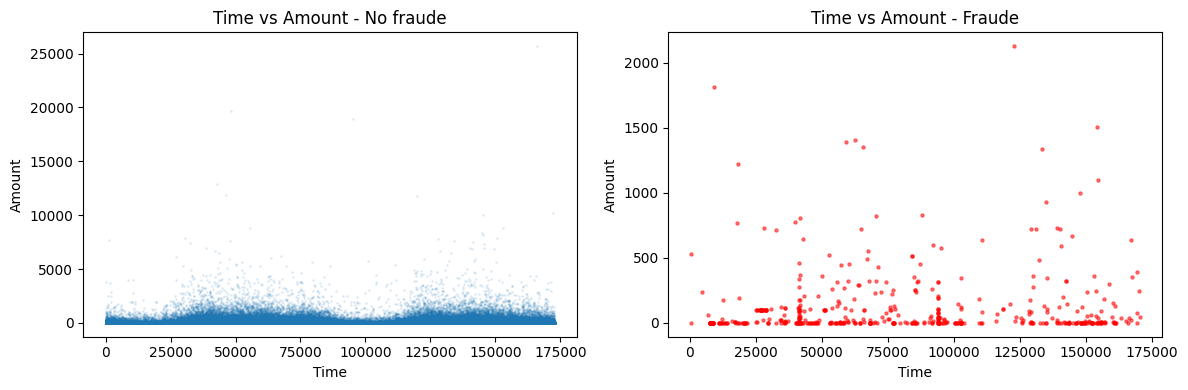

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df[df['es_fraude'] == 0]['Time'], df[df['es_fraude'] == 0]['Amount'], alpha=0.1, s=1)
axes[0].set_title('Time vs Amount - No fraude')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Amount')

axes[1].scatter(df[df['es_fraude'] == 1]['Time'], df[df['es_fraude'] == 1]['Amount'], alpha=0.5, s=5, color='red')
axes[1].set_title('Time vs Amount - Fraude')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Amount')

plt.tight_layout()
plt.show()

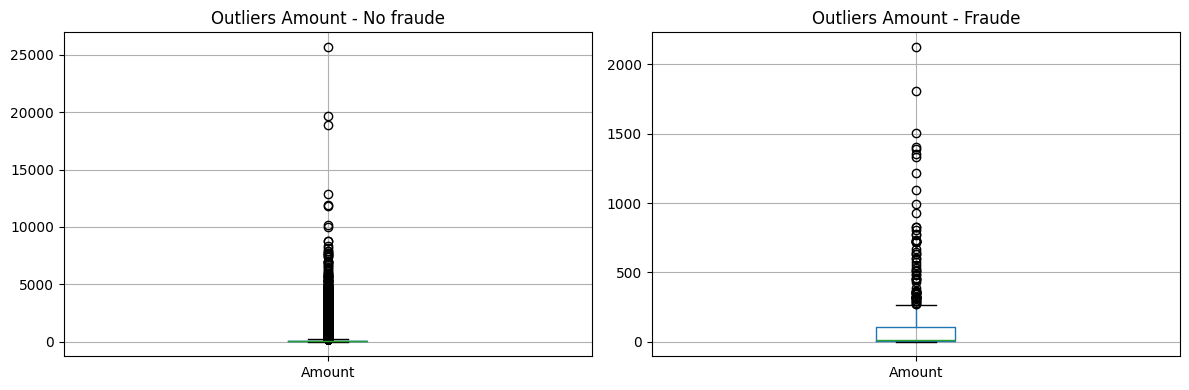

In [6]:
# Boxplot de Amount por clase
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[df['es_fraude'] == 0].boxplot(column='Amount', ax=axes[0])
axes[0].set_title('Outliers Amount - No fraude')

df[df['es_fraude'] == 1].boxplot(column='Amount', ax=axes[1])
axes[1].set_title('Outliers Amount - Fraude')

plt.tight_layout()
plt.show()

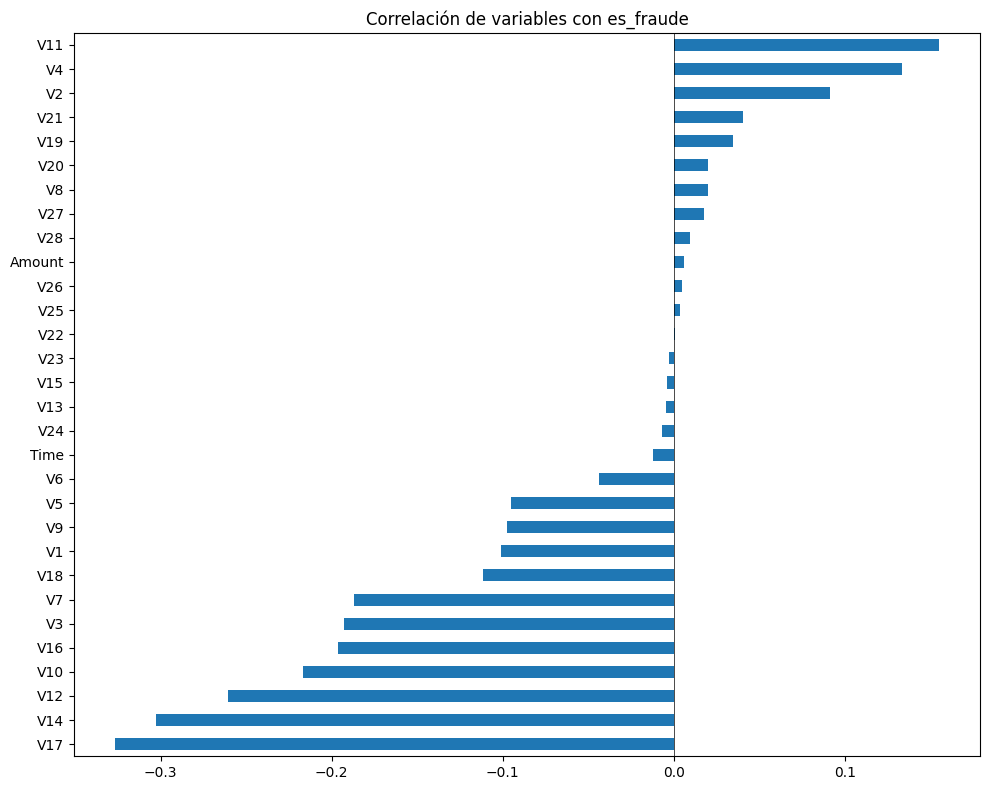

In [7]:
# Correlaciones de todas las variables con es_fraude
correlaciones = df.corr()['es_fraude'].drop('es_fraude').sort_values()

plt.figure(figsize=(10, 8))
correlaciones.plot(kind='barh')
plt.title('Correlación de variables con es_fraude')
plt.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

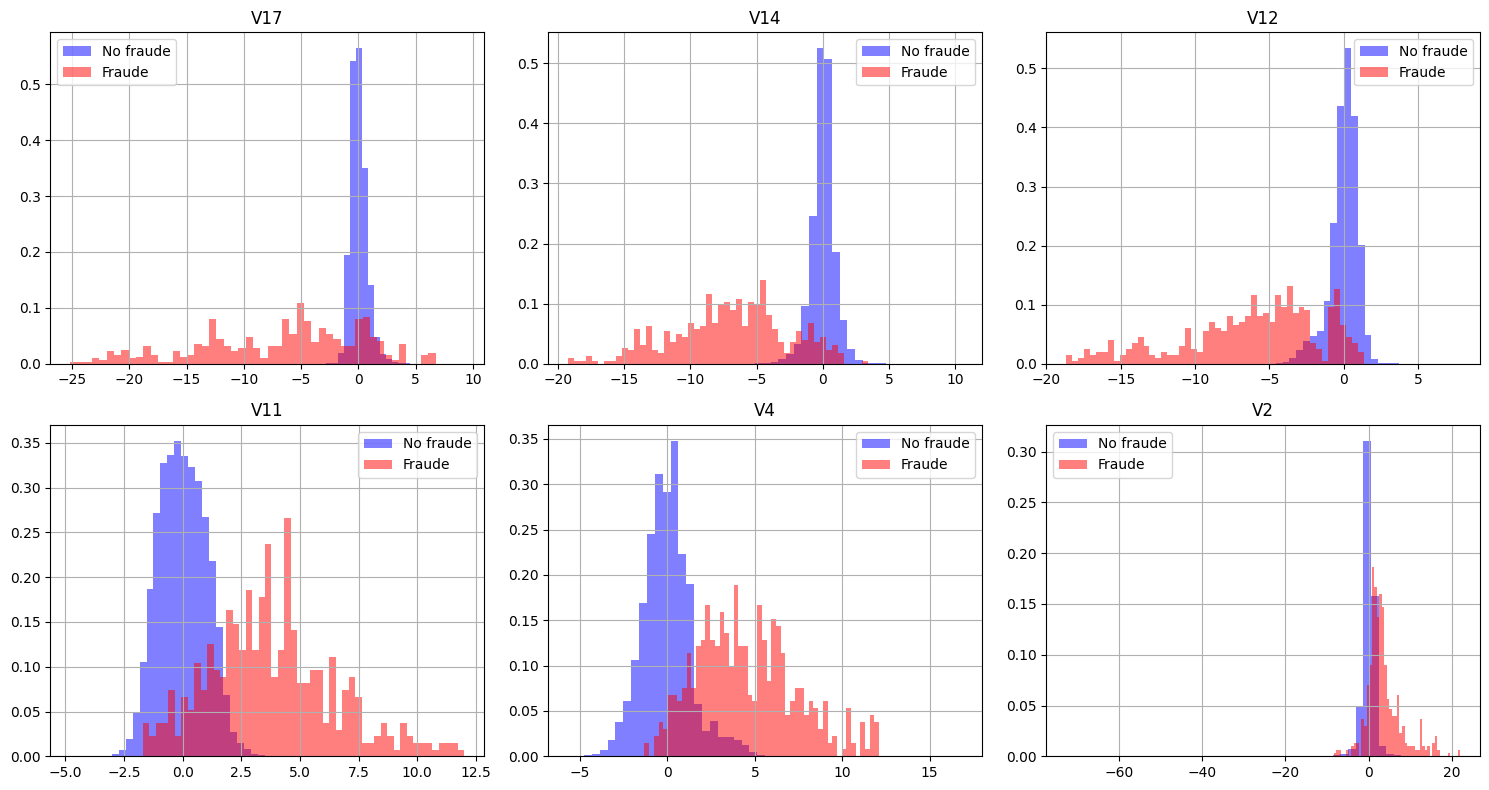

In [12]:
# Distribuciones de las variables más correlacionadas
variables = ['V17', 'V14', 'V12', 'V11', 'V4', 'V2']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, var in enumerate(variables):
    df[df['es_fraude'] == 0][var].hist(bins=50, ax=axes[i], alpha=0.5, label='No fraude', color='blue', density=True)
    df[df['es_fraude'] == 1][var].hist(bins=50, ax=axes[i], alpha=0.5, label='Fraude', color='red', density=True)
    axes[i].set_title(var)
    axes[i].legend()

plt.tight_layout()
plt.show()